# Weather Trends in Milan (1995–2025)

### A Historical Temperature Analysis Using Python

**Course:** Coding for Data Science and Data Management  
**Academic Year:** 2026/27  
**University:** University of Milan

---

## 1. Introduction

This project investigates how temperatures in Milan have changed
between 1995 and 2025.

Using historical weather data from Open-Meteo, we examine
long-term temperature trends, seasonal variations, and the
frequency of unusually hot days.

The analysis is implemented in Python using pandas, numpy,
and matplotlib.

## 2. Research Questions

The project addresses five research questions:

1. How has Milan's annual average temperature changed since 1995?
2. Which years were the warmest and coldest?
3. Which months have the highest and lowest temperatures?
4. Has the number of days reaching 30°C changed over time?
5. How do temperatures in 1995–2004 compare with 2016–2025?

## Data Source

**Source:** Open-Meteo Historical Weather API

https://open-meteo.com/en/docs/historical-weather-api

**Location:** Milan, Italy  
**Latitude:** 45.4642  
**Longitude:** 9.1900  
**Period:** January 1, 1995 – December 31, 2025

Variables:
- Daily mean temperature (°C)
- Daily maximum temperature (°C)

The historical API provides gridded weather estimates.
These are not necessarily direct measurements from a
single weather station.

In [1]:
# Import Path for working with folders.
from pathlib import Path

# Import sys to configure Python's import path.
import sys

# Import pandas and numpy for notebook calculations.
import pandas as pd
import numpy as np

# Import matplotlib for additional notebook plots.
import matplotlib.pyplot as plt

# Find the main project folder.
PROJECT_ROOT = Path.cwd().resolve()

# If the notebook runs inside notebooks/, go one folder up.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add the project folder to Python's import path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Use the project root for relative data/output paths.
import os
os.chdir(PROJECT_ROOT)

# Import data loading functions.
from src.data_loader import load_weather_data

# Import data processing functions.
from src.data_processing import (
    clean_weather_data,
    check_data_completeness
)

# Import statistical analysis functions.
from src.analysis import (
    calculate_annual_temperatures,
    calculate_monthly_temperatures,
    calculate_hot_days,
    calculate_temperature_trend,
    calculate_summary_statistics,
    compare_decades
)

# Import plotting functions.
from src.visualization import (
    plot_annual_temperature,
    plot_monthly_temperature,
    plot_temperature_heatmap,
    plot_hot_days
)

print("All libraries and modules imported successfully.")

All libraries and modules imported successfully.


## 3. Data Collection

Historical weather observations are retrieved using the
Open-Meteo API.

The data loader checks whether a CSV file already exists
in the `data/` directory.

If the file exists, it is loaded locally. Otherwise,
the program downloads the observations and saves them
for future use.

This approach avoids unnecessary API requests and makes
the analysis reproducible.

In [2]:
# Load the original weather dataset.
raw_data = load_weather_data()

# Display the number of observations.
print("Number of observations:", len(raw_data))

# Display the column names.
print("\nDataset columns:")
print(raw_data.columns.tolist())

# Display the first five rows.
display(raw_data.head())

Loading weather data from CSV...
Number of observations: 11323

Dataset columns:
['time', 'temperature_2m_mean', 'temperature_2m_max']


,time,temperature_2m_mean,temperature_2m_max
0,1995-01-01,5.3,10.6
1,1995-01-02,2.3,5.7
2,1995-01-03,0.9,5.1
3,1995-01-04,-0.9,3.3
4,1995-01-05,-2.0,3.0


## 4. Data Cleaning and Preparation

Before performing statistical analysis, the dataset must
be checked for errors and missing observations.

The cleaning procedure includes:

- Converting dates to datetime format.
- Converting temperatures to numeric values.
- Removing duplicate dates.
- Removing rows with missing required values.
- Sorting observations chronologically.
- Creating year and month columns.

The cleaning operations are implemented in
`src/data_processing.py`.

In [3]:
# Clean the raw weather observations.
weather = clean_weather_data(raw_data)

# Display the first five cleaned observations.
display(weather.head())

# Display information about the dataset.
print("\nDataset information:")
weather.info()

# Calculate descriptive statistics.
print("\nDescriptive statistics:")
display(weather[["mean_temp", "max_temp"]].describe())


Missing values before cleaning:
date         0
mean_temp    0
max_temp     0
dtype: int64

Cleaned dataset:
        date  mean_temp  max_temp  year  month
0 1995-01-01        5.3      10.6  1995      1
1 1995-01-02        2.3       5.7  1995      1
2 1995-01-03        0.9       5.1  1995      1
3 1995-01-04       -0.9       3.3  1995      1
4 1995-01-05       -2.0       3.0  1995      1

Total valid observations: 11323


,date,mean_temp,max_temp,year,month
0,1995-01-01,5.3,10.6,1995,1
1,1995-01-02,2.3,5.7,1995,1
2,1995-01-03,0.9,5.1,1995,1
3,1995-01-04,-0.9,3.3,1995,1
4,1995-01-05,-2.0,3.0,1995,1



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11323 entries, 0 to 11322
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       11323 non-null  datetime64[us]
 1   mean_temp  11323 non-null  float64       
 2   max_temp   11323 non-null  float64       
 3   year       11323 non-null  int32         
 4   month      11323 non-null  int32         
dtypes: datetime64[us](1), float64(2), int32(2)
memory usage: 354.0 KB

Descriptive statistics:


,mean_temp,max_temp
count,11323.000000,11323.000000
mean,13.172516,17.811410
std,8.037519,8.433404
min,-7.800000,-3.200000
25%,6.200000,10.600000
50%,13.300000,17.800000
75%,19.900000,24.700000
max,31.800000,38.400000


In [4]:
# Calculate the number of observations per year.
completeness = check_data_completeness(weather)

# Verify that every expected year is represented.
expected_years = set(range(1995, 2026))
observed_years = set(completeness["year"])

missing_years = sorted(expected_years - observed_years)

if missing_years:
    raise ValueError(
        f"Missing years: {missing_years}"
    )

# Require at least 95% of daily observations per year.
incomplete_years = completeness[
    completeness["completeness_pct"] < 95
]

if not incomplete_years.empty:
    raise ValueError(
        "Some years have less than 95% coverage."
    )

print("All 31 years are represented.")
print("Every year has at least 95% data coverage.")

display(completeness.tail())


Data completeness by year:
    year  observed_days  expected_days  completeness_pct
0   1995            365            365             100.0
1   1996            366            366             100.0
2   1997            365            365             100.0
3   1998            365            365             100.0
4   1999            365            365             100.0
5   2000            366            366             100.0
6   2001            365            365             100.0
7   2002            365            365             100.0
8   2003            365            365             100.0
9   2004            366            366             100.0
10  2005            365            365             100.0
11  2006            365            365             100.0
12  2007            365            365             100.0
13  2008            366            366             100.0
14  2009            365            365             100.0
15  2010            365            365             100.0
16 

,year,observed_days,expected_days,completeness_pct
26,2021,365,365,100.0
27,2022,365,365,100.0
28,2023,365,365,100.0
29,2024,366,366,100.0
30,2025,365,365,100.0


## 5. Statistical Analysis

We use pandas and numpy to calculate:

1. Annual average temperatures.
2. Average temperatures for each calendar month.
3. Annual counts of hot days.
4. The linear temperature trend.
5. Descriptive statistics.

A hot day is defined as a day with a maximum temperature
of at least 30°C.

The linear trend is estimated using `numpy.polyfit()`.

The resulting slope is multiplied by 10 to express
temperature change in degrees Celsius per decade.

In [5]:
# Calculate average temperature for each year.
annual = calculate_annual_temperatures(weather)

# Calculate average temperature for each calendar month.
monthly = calculate_monthly_temperatures(weather)

# Count hot days for each year.
hot_days = calculate_hot_days(weather)

# Calculate the linear temperature trend.
trend, fitted_values = calculate_temperature_trend(
    annual
)

# Calculate descriptive statistics.
statistics = calculate_summary_statistics(
    annual,
    hot_days
)

# Display the results.
print("Temperature trend:", round(trend, 3), "°C/decade")

print("\nSummary statistics:")
display(pd.DataFrame([statistics]).T)

print("\nAnnual temperatures:")
display(annual.head())

Temperature trend: 0.725 °C/decade

Summary statistics:


,0
average_annual_temp,13.172659
standard_deviation,0.838971
warmest_year,2022.000000
warmest_temperature,14.990411
coldest_year,1996.000000
coldest_temperature,11.831967
most_hot_days_year,2003.000000
most_hot_days_count,67.000000



Annual temperatures:


,year,annual_mean
0,1995,11.970959
1,1996,11.831967
2,1997,12.893151
3,1998,12.452329
4,1999,12.455342


### 5.1 Correlation and R-squared

The Pearson correlation coefficient measures the strength
and direction of the linear relationship between year
and annual mean temperature.

R-squared measures the proportion of variation in annual
temperatures explained by the fitted linear trend.

In [6]:
# Calculate the Pearson correlation coefficient
# between year and annual mean temperature.
correlation = np.corrcoef(
    annual["year"],
    annual["annual_mean"]
)[0, 1]

print(f"Correlation coefficient: {correlation:.3f}")

# Calculate the coefficient of determination.
r_squared = correlation ** 2

print(f"R-squared: {r_squared:.3f}")

Correlation coefficient: 0.785
R-squared: 0.617


## 6. Data Visualization

### 6.1 Annual Temperature Trend

The first chart shows Milan's average annual temperature
from 1995 to 2025.

The blue line represents the observed annual averages,
while the dashed red line represents the fitted linear trend.

This visualization helps identify long-term temperature
changes and year-to-year variability.

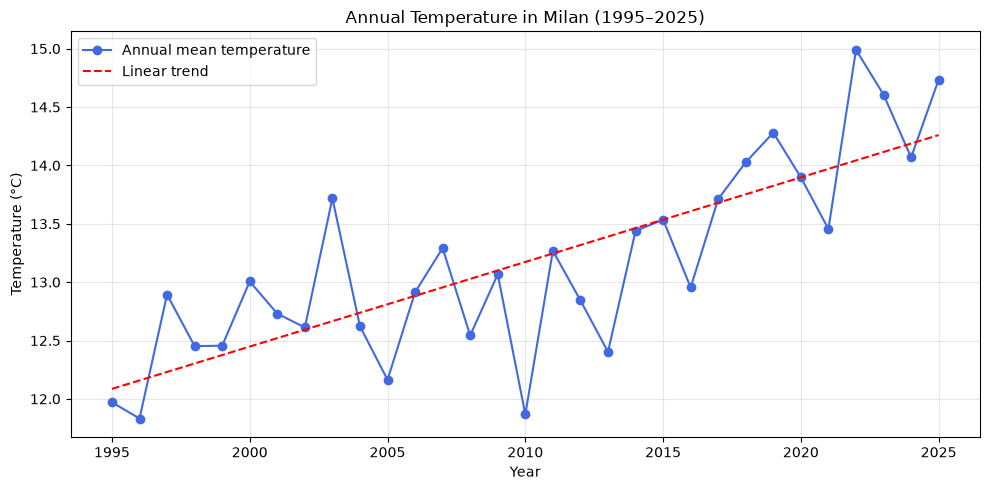

Estimated trend: +0.725 °C per decade
The fitted trend is increasing.


In [7]:
# Generate the annual temperature chart.
plot_annual_temperature(annual, fitted_values)

# Display the estimated linear trend.
print(f"Estimated trend: {trend:+.3f} °C per decade")

# Explain the direction of the fitted trend.
if trend > 0:
    print("The fitted trend is increasing.")
elif trend < 0:
    print("The fitted trend is decreasing.")
else:
    print("The fitted trend is approximately flat.")

### 6.2 Seasonal Temperature Patterns

The second chart compares average temperatures
across the twelve calendar months.

It helps identify the warmest and coldest parts
of the year and illustrates Milan's seasonal cycle.

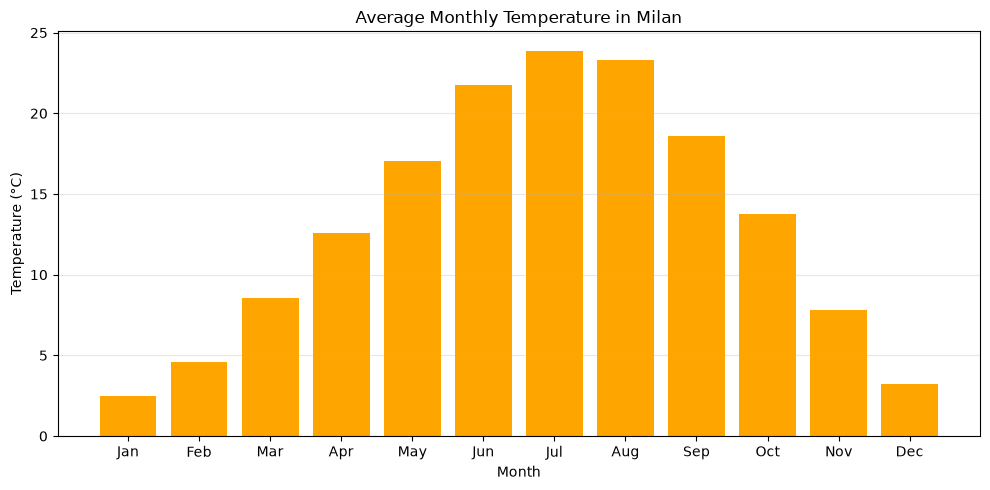

Warmest month number: 7
Coldest month number: 1


In [8]:
# Generate the monthly temperature chart.
plot_monthly_temperature(monthly)

# Identify the warmest month.
warmest_month = monthly.loc[
    monthly["mean_temp"].idxmax()
]

# Identify the coldest month.
coldest_month = monthly.loc[
    monthly["mean_temp"].idxmin()
]

print("Warmest month number:", int(warmest_month["month"]))
print("Coldest month number:", int(coldest_month["month"]))

### 6.3 Monthly Temperature Heatmap

The heatmap displays average monthly temperatures
for every year between 1995 and 2025.

Each row represents a year and each column
represents a calendar month.

The color scale makes it easier to compare seasonal
temperatures across different years.

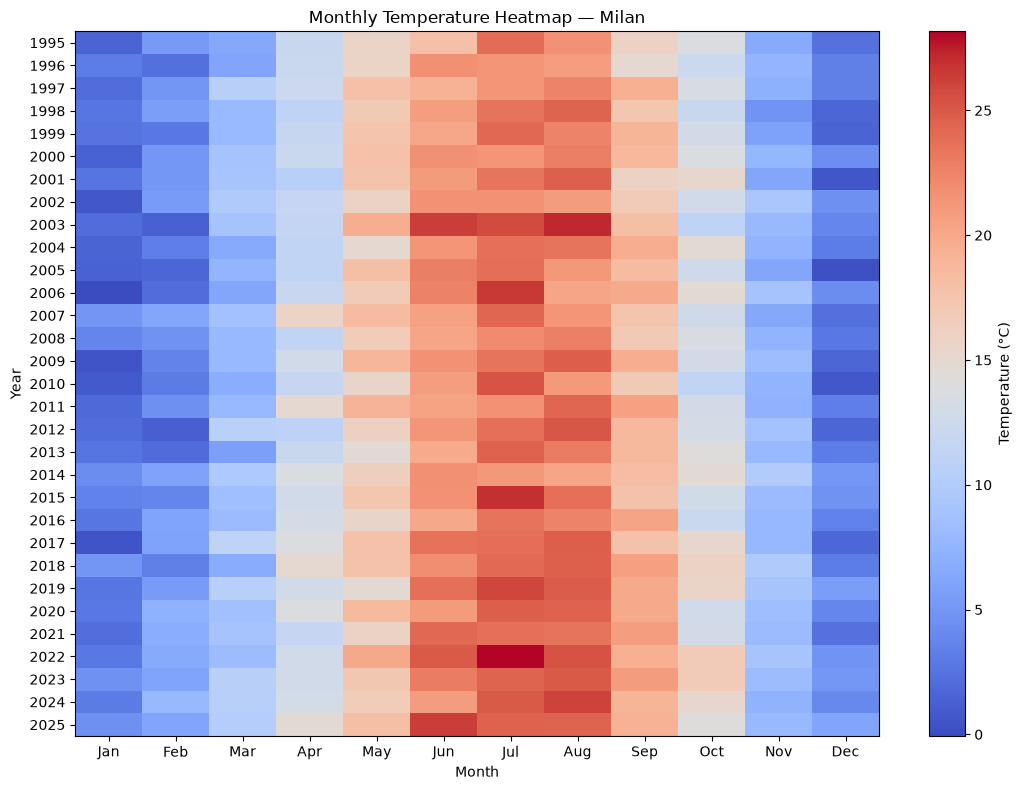

In [9]:
# Generate the temperature heatmap.
plot_temperature_heatmap(weather)

### 6.4 Frequency of Hot Days

A hot day is defined as a day when the daily maximum
temperature reaches at least 30°C.

This chart displays the number of hot days recorded
during each year.

It helps investigate whether the frequency of
hot days has changed over the study period.

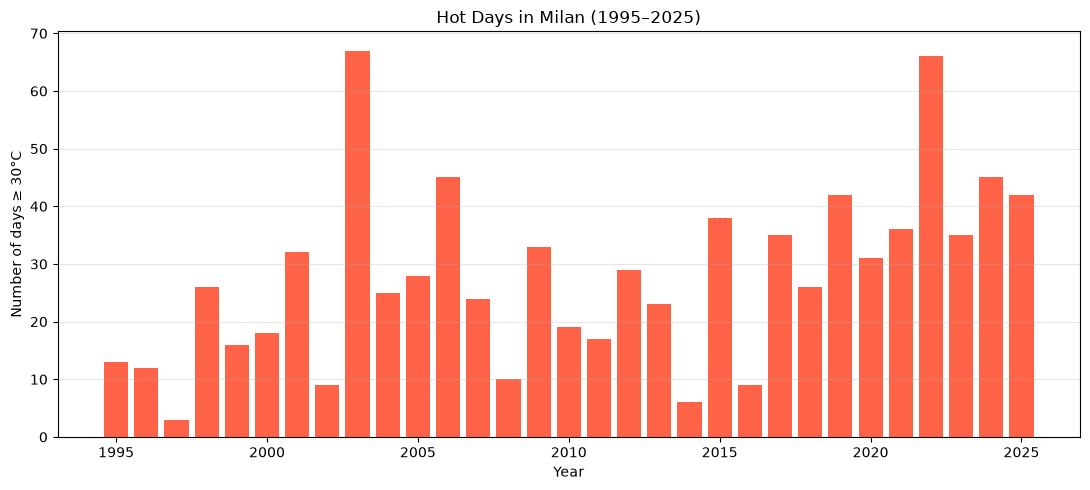

Year with the most hot days: 2003
Number of hot days: 67


In [10]:
# Generate the hot-day bar chart.
plot_hot_days(hot_days)

# Find the year with the highest number of hot days.
maximum_hot_days = hot_days.loc[
    hot_days["hot_days"].idxmax()
]

print(
    "Year with the most hot days:",
    int(maximum_hot_days["year"])
)

print(
    "Number of hot days:",
    int(maximum_hot_days["hot_days"])
)

In [11]:
# Estimate the linear trend in annual hot-day counts.
hot_day_slope, intercept = np.polyfit(
    hot_days["year"],
    hot_days["hot_days"],
    1
)

# Convert the annual trend into a trend per decade.
hot_day_trend = hot_day_slope * 10

print(f"Hot-day trend: {hot_day_trend:+.2f} days per decade")

# Interpret the direction of the trend.
if hot_day_trend > 0:
    print("The frequency of hot days shows an increasing trend.")
elif hot_day_trend < 0:
    print("The frequency of hot days shows a decreasing trend.")
else:
    print("The frequency of hot days shows no linear trend.")

Hot-day trend: +7.91 days per decade
The frequency of hot days shows an increasing trend.


## 7. Comparison of Two Historical Periods

To investigate longer-term temperature differences,
we compare two ten-year periods:

- **1995–2004:** Earlier period
- **2016–2025:** Recent period

We calculate the mean annual temperature for each period
and subtract the earlier average from the recent average.

A positive difference indicates that the recent period
was warmer on average.

In [12]:
# Compare the two historical periods.
comparison = compare_decades(annual)

# Create a small table containing the period averages.
comparison_table = pd.DataFrame({
    "Period": ["1995–2004", "2016–2025"],
    "Average temperature (°C)": [
        comparison["1995_2004"],
        comparison["2016_2025"]
    ]
})

# Display the comparison table.
display(comparison_table.round(2))

# Display the difference between periods.
print(
    "Temperature difference:",
    f"{comparison['difference']:+.2f} °C"
)

,Period,Average temperature (°C)
0,1995–2004,12.63
1,2016–2025,14.07


Temperature difference: +1.44 °C


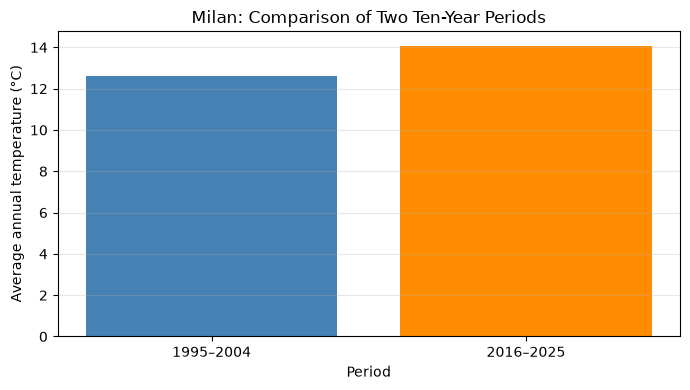

In [13]:
# Create a figure and axes.
fig, ax = plt.subplots(figsize=(7, 4))

# Plot the average temperature of each period.
ax.bar(
    comparison_table["Period"],
    comparison_table["Average temperature (°C)"],
    color=["steelblue", "darkorange"]
)

# Add the title and labels.
ax.set_title("Milan: Comparison of Two Ten-Year Periods")
ax.set_ylabel("Average annual temperature (°C)")
ax.set_xlabel("Period")

# Add horizontal grid lines.
ax.grid(axis="y", alpha=0.3)

# Adjust spacing.
fig.tight_layout()

# Save the chart.
fig.savefig(
    PROJECT_ROOT / "outputs" / "decade_comparison.png",
    dpi=300
)

# Display the chart.
plt.show()

# Close the figure.
plt.close(fig)

In [14]:
# Print the key numerical results.
print("MILAN WEATHER ANALYSIS — KEY FINDINGS")
print("-" * 45)

print(
    f"Average annual temperature: "
    f"{statistics['average_annual_temp']:.2f} °C"
)

print(
    f"Warmest year: {statistics['warmest_year']} "
    f"({statistics['warmest_temperature']:.2f} °C)"
)

print(
    f"Coldest year: {statistics['coldest_year']} "
    f"({statistics['coldest_temperature']:.2f} °C)"
)

print(
    f"Temperature trend: {trend:+.2f} °C/decade"
)

print(
    f"Difference between periods: "
    f"{comparison['difference']:+.2f} °C"
)

MILAN WEATHER ANALYSIS — KEY FINDINGS
---------------------------------------------
Average annual temperature: 13.17 °C
Warmest year: 2022 (14.99 °C)
Coldest year: 1996 (11.83 °C)
Temperature trend: +0.72 °C/decade
Difference between periods: +1.44 °C


## 8. Conclusion

The analysis reveals an increasing temperature trend
in Milan between 1995 and 2025.

### Key Findings

- The average annual temperature was 13.17°C.
- The estimated temperature trend was +0.72°C per decade.
- The warmest year was 2022 (14.99°C).
- The coldest year was 1996 (11.83°C).
- July was the warmest month, while January was the coldest.
- The highest number of hot days occurred in 2003,
  with 67 days reaching at least 30°C.
- The period 2016–2025 was approximately 1.44°C warmer
  than 1995–2004.
- The Pearson correlation coefficient was 0.785,
  indicating a strong positive linear relationship
  between year and annual mean temperature.
- The R-squared value was 0.617, meaning that the
  fitted linear trend explains approximately 61.7%
  of the variation in annual mean temperatures.
- The estimated hot-day trend was [VALUE] days per decade.

### Limitations

The dataset consists of historical gridded weather
estimates rather than direct weather-station measurements.

The analysis focuses on one geographical location.
Correlation and linear trends do not establish causation.

### Future Improvements

Future work could include precipitation analysis,
extreme weather events, and comparisons with other
European cities.

## 9. Exporting Results

The processed dataset and calculated statistics
can be exported as CSV files.

This allows the analysis to be reproduced or extended
without repeating all calculations.

In [15]:
# Define the output directory.
output_dir = PROJECT_ROOT / "outputs"

# Create the directory if necessary.
output_dir.mkdir(parents=True, exist_ok=True)

# Export cleaned observations.
weather.to_csv(
    output_dir / "cleaned_weather.csv",
    index=False
)

# Export annual temperatures.
annual.to_csv(
    output_dir / "annual_statistics.csv",
    index=False
)

# Export monthly temperatures.
monthly.to_csv(
    output_dir / "monthly_statistics.csv",
    index=False
)

# Export hot-day counts.
hot_days.to_csv(
    output_dir / "hot_days_statistics.csv",
    index=False
)

print("All analysis results exported successfully.")

All analysis results exported successfully.
